# Modularity on the Karate Club Graph
**DSC212: Graph Theory — Research Assignment**

This notebook implements **recursive spectral modularity bisection** from scratch (NumPy + NetworkX only) on Zachary's Karate Club network, following Newman (2006), *"Modularity and community structure in networks"*, PNAS 103(23):8577–8582.

**Pipeline**
1. Build `A`, `k`, `m` and the modularity matrix `B = A - k kᵀ / 2m`
2. Split a group using the sign of the leading eigenvector of its restricted matrix `B(C)`; stop when `λ₁ ≤ 0`
3. Recurse, saving a snapshot after every split
4. Visualize each snapshot with a fixed layout
5. Compute degree / betweenness / closeness / clustering after each split and plot their evolution
6. Discussion

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from collections import deque

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 110

## 1. Load the graph and build the modularity matrix

In [2]:
G = nx.karate_club_graph()          # 34 nodes (0..33), 78 edges
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = sorted(G.nodes())
print(f"n = {n}, m = {m}")

# Ground truth (what actually happened after the split)
truth = {v: G.nodes[v]['club'] for v in G.nodes}          # 'Mr. Hi' or 'Officer'
print({c: sum(1 for v in truth if truth[v]==c) for c in set(truth.values())})

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # 0/1 adjacency (newer NetworkX attaches edge weights; ignore them)
k = A.sum(axis=1)                          # degree vector
B = A - np.outer(k, k) / (2*m)             # modularity matrix

# Sanity checks from the handout's propositions
print("B symmetric (Prop. 1):        ", np.allclose(B, B.T))
print("B @ 1 = 0 (Prop. 2):          ", np.allclose(B @ np.ones(n), 0))
print("Sum of degrees = 2m:          ", k.sum() == 2*m)
print("Largest eigenvalue of B:      ", np.linalg.eigvalsh(B)[-1])

n = 34, m = 78
{'Officer': 17, 'Mr. Hi': 17}
B symmetric (Prop. 1):         True
B @ 1 = 0 (Prop. 2):           True
Sum of degrees = 2m:           True
Largest eigenvalue of B:       4.977080225729882


## 2. Spectral bisection of one group

For a group `C` (list of node indices), the restricted matrix is the block `B[C][:, C]`.

* Compute the eigen-decomposition with `np.linalg.eigh` (valid because `B(C)` is real symmetric — Theorem 1). It returns eigenvalues in ascending order, so the leading pair is the **last** one.
* If `λ₁ ≤ 0` → indivisible (Theorem 3).
* Otherwise `s_i = +1` if `(u₁)_i > 0` else `-1`.
* If the sign split puts everyone on one side, the group is also treated as indivisible.
* Modularity gain `ΔQ = sᵀ B(C) s / 4m`.

The handout restricts `B` to the block directly. Newman's paper actually uses the *generalized* matrix `B⁽ᶜ⁾_ij = B_ij − δ_ij Σ_{l∈C} B_il`, which makes `ΔQ` exact. I implement both via a flag: the **handout version is the main result**, and the corrected version is compared in Section 8.

In [3]:
EPS = 1e-10

def restricted_B(B, C, newman_correction=False):
    """Block of B for group C. Optionally apply Newman's diagonal correction."""
    idx = np.array(C)
    BC = B[np.ix_(idx, idx)].copy()
    if newman_correction:
        BC -= np.diag(BC.sum(axis=1))
    return BC

def bisect(B, C, newman_correction=False):
    """Try to split group C. Returns (C_plus, C_minus, lambda1, dQ) or None if indivisible."""
    BC = restricted_B(B, C, newman_correction)
    vals, vecs = np.linalg.eigh(BC)            # ascending eigenvalues
    lam1, u1 = vals[-1], vecs[:, -1]
    if lam1 <= EPS:                            # stopping rule (Theorem 3)
        return None, lam1
    s = np.where(u1 > 0, 1, -1)                # threshold back to +/-1
    if abs(s.sum()) == len(s):                 # all on one side -> no real split
        return None, lam1
    dQ = s @ BC @ s / (4*m)
    if newman_correction and dQ <= EPS:        # Newman's extra safeguard: reject splits that do not raise Q
        return None, lam1
    C_arr = np.array(C)
    return (C_arr[s == 1].tolist(), C_arr[s == -1].tolist(), lam1, dQ), lam1

## 3. Recursive bisection (one snapshot per split)

In [4]:
def recursive_bisection(B, newman_correction=False, verbose=True):
    """Returns (final_communities, history). history[t] = partition after t-th split (t=0: whole graph)."""
    queue = deque([list(range(n))])
    final = []
    history = [[list(range(n))]]
    log = []
    while queue:
        C = queue.popleft()
        if len(C) < 2:
            final.append(C); continue
        res, lam1 = bisect(B, C, newman_correction)
        if res is None:
            final.append(C)
            if verbose: print(f"  group of size {len(C):2d}: lambda1 = {lam1: .4f} -> indivisible")
            continue
        Cp, Cm, lam1, dQ = res
        if verbose: print(f"  group of size {len(C):2d}: lambda1 = {lam1: .4f} -> split {len(Cp)} / {len(Cm)}   (dQ = {dQ:.4f})")
        queue.extend([Cp, Cm])
        # current partition = finished groups + groups still in queue
        history.append([sorted(g) for g in final + list(queue)])
        log.append(dict(split=len(history)-1, parent_size=len(C), lambda1=lam1,
                        child_sizes=(len(Cp), len(Cm)), dQ=dQ))
    return [sorted(g) for g in final], history, log

print("Recursive spectral bisection (handout version):")
communities, history, log = recursive_bisection(B)
print(f"\nFound {len(communities)} communities:")
for i, c in enumerate(sorted(communities, key=lambda c: c[0])):
    print(f"  C{i+1} (size {len(c)}): {c}")

Recursive spectral bisection (handout version):
  group of size 34: lambda1 =  4.9771 -> split 16 / 18   (dQ = 0.3715)
  group of size 16: lambda1 =  2.9441 -> split 10 / 6   (dQ = 0.1112)
  group of size 18: lambda1 =  2.5041 -> split 5 / 13   (dQ = 0.1112)
  group of size 10: lambda1 =  2.5712 -> indivisible
  group of size  6: lambda1 =  2.1480 -> split 1 / 5   (dQ = 0.0338)
  group of size  5: lambda1 =  1.8759 -> indivisible
  group of size 13: lambda1 =  2.3563 -> indivisible
  group of size  5: lambda1 =  2.1470 -> indivisible

Found 5 communities:
  C1 (size 10): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  C2 (size 5): [4, 5, 6, 10, 16]
  C3 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  C4 (size 1): [11]
  C5 (size 5): [24, 25, 27, 28, 31]


In [5]:
def modularity_Q(partition):
    """Q = (1/2m) sum_ij B_ij delta(c_i,c_j)  (general form; reduces to sᵀBs/4m for 2 groups)."""
    Q = 0.0
    for g in partition:
        idx = np.array(g)
        Q += B[np.ix_(idx, idx)].sum()
    return Q / (2*m)

Qs = [modularity_Q(p) for p in history]
# cross-check against NetworkX's implementation
nxQ = [nx.community.modularity(G, [set(g) for g in p], weight=None) for p in history]
pd.DataFrame({'split': range(len(history)), '#communities': [len(p) for p in history],
              'Q (mine)': Qs, 'Q (networkx)': nxQ})

,split,#communities,Q (mine),Q (networkx)
0,0,1,-2.419717e-17,0.000000
1,1,2,3.714661e-01,0.371466
2,2,3,3.897929e-01,0.389793
3,3,4,4.081197e-01,0.408120
4,4,5,4.094346e-01,0.409435


## 4. Visualize the graph after each split (fixed spring layout)

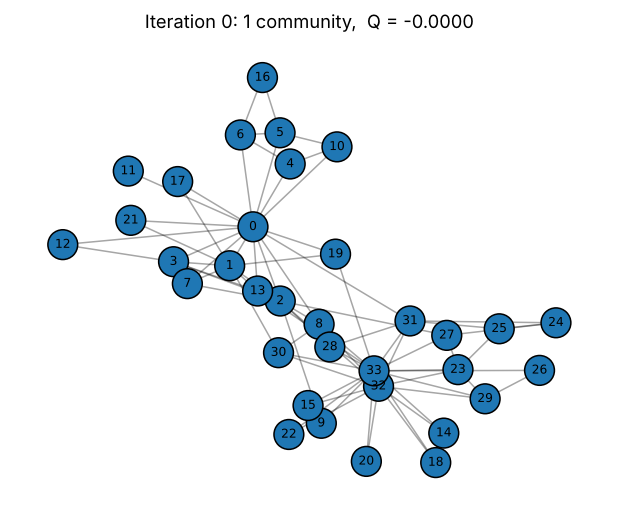

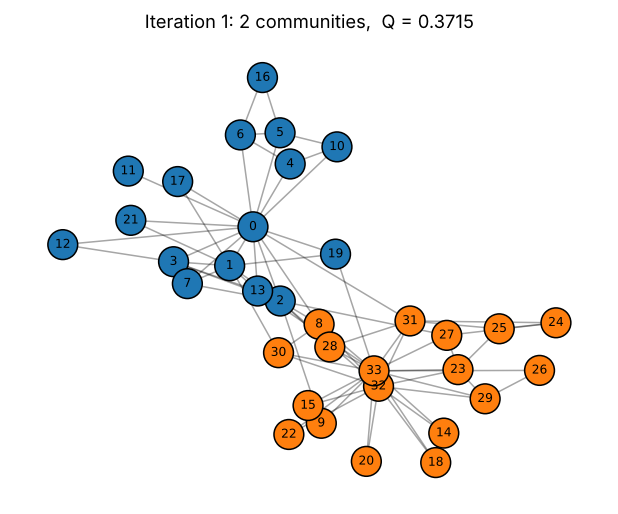

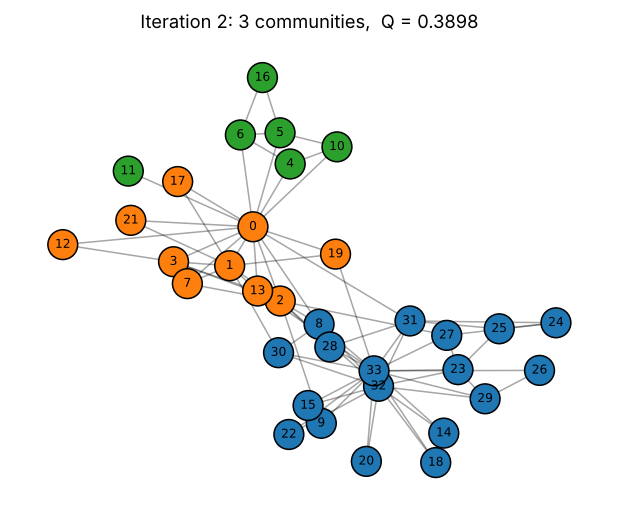

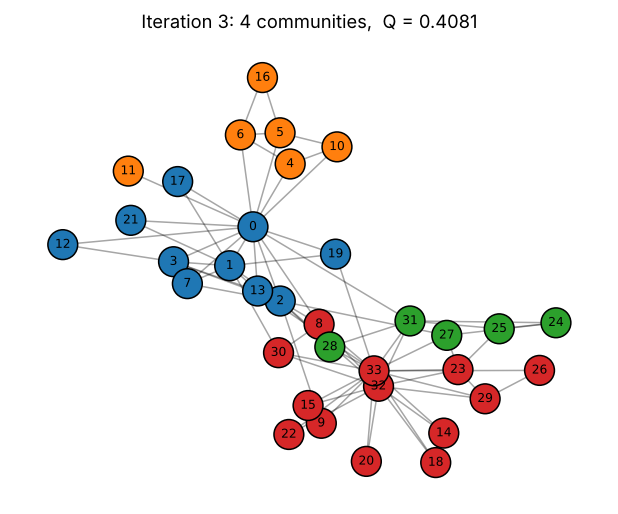

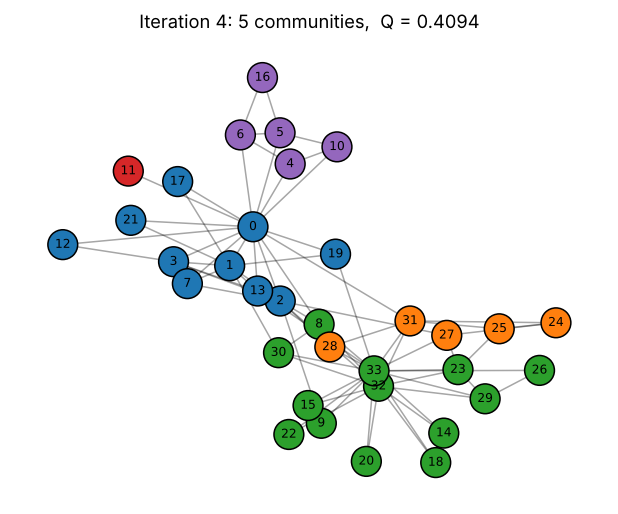

In [6]:
pos = nx.spring_layout(G, seed=42)          # fixed layout reused for every figure
palette = plt.cm.tab10.colors

def draw_partition(partition, title, ax):
    color_of = {}
    for ci, g in enumerate(partition):
        for v in g: color_of[v] = palette[ci % 10]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[color_of[v] for v in G.nodes], node_size=380, edgecolors='k')
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
    ax.set_title(title); ax.axis('off')

for t, part in enumerate(history):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    draw_partition(part, f"Iteration {t}: {len(part)} communit{'y' if len(part)==1 else 'ies'},  Q = {Qs[t]:.4f}", ax)
    plt.show()

### Final partition vs. the real split

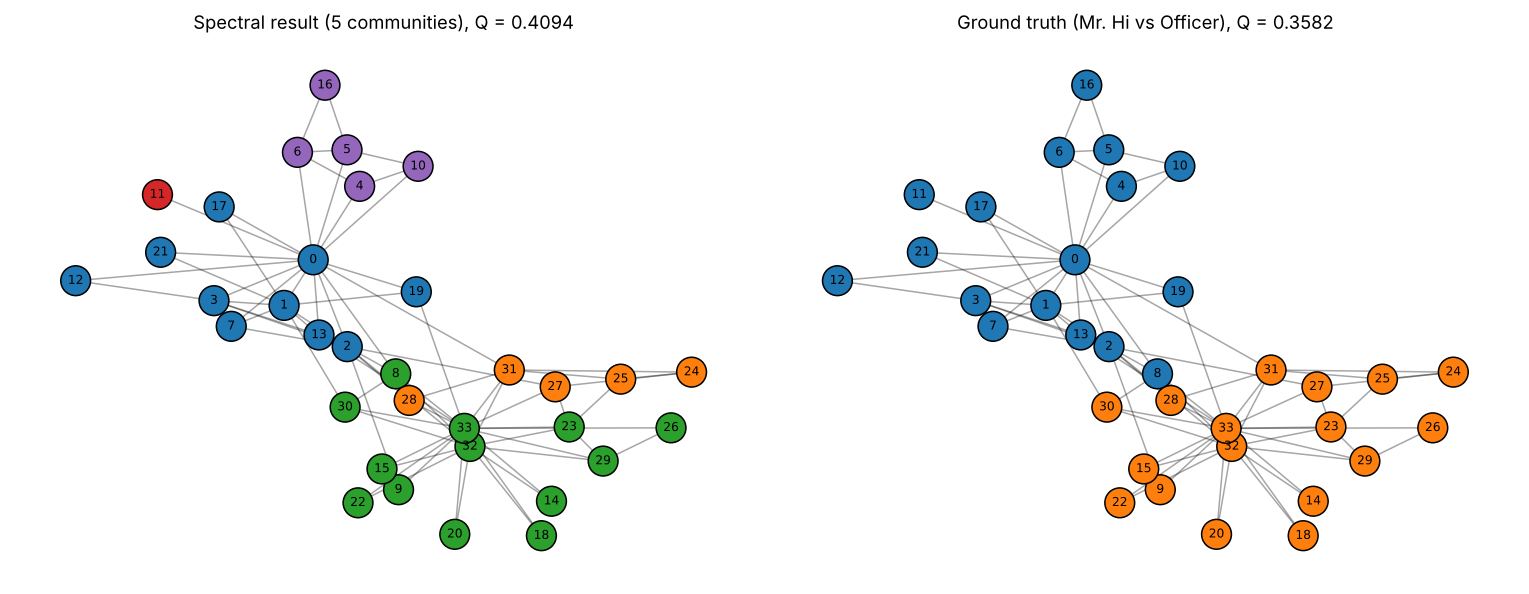

First (2-way) split agrees with the real split on 33/34 members; misclassified: [8]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
draw_partition(communities, f"Spectral result ({len(communities)} communities), Q = {modularity_Q(communities):.4f}", axes[0])
real = [[v for v in G.nodes if truth[v]=='Mr. Hi'], [v for v in G.nodes if truth[v]=='Officer']]
draw_partition(real, f"Ground truth (Mr. Hi vs Officer), Q = {modularity_Q(real):.4f}", axes[1])
plt.tight_layout(); plt.show()

# How well does the FIRST split match the real fission?
first = history[1]
def agreement(p2):
    lab = {v: i for i, g in enumerate(p2) for v in g}
    hi = [v for v in G.nodes if truth[v]=='Mr. Hi']
    same = sum(1 for v in G.nodes if (lab[v]==lab[hi[0]]) == (truth[v]=='Mr. Hi'))
    return same
agree = agreement(first)
mis = [v for v in G.nodes if ((v in first[0]) == (0 in first[0])) != (truth[v]=='Mr. Hi')]
print(f"First (2-way) split agrees with the real split on {agree}/{n} members; misclassified: {mis}")

## 5. Node metrics after each split

**Design choice.** The metrics must change after a split, but NetworkX metrics computed on the full `G` never would. So at iteration `t` I compute them on the graph **`H_t` = `G` with all edges between different communities removed** (same 34 nodes). This measures each node's position *inside its own community*. At `t = 0` there are no cuts, so `H_0 = G`.

*Note:* in `H_t` communities are disconnected from each other; NetworkX's closeness uses the Wasserman–Faust scaling by default, which handles disconnected graphs sensibly.

In [8]:
def community_graph(partition):
    lab = {v: i for i, g in enumerate(partition) for v in g}
    H = nx.Graph(); H.add_nodes_from(G.nodes)
    H.add_edges_from((u, v) for u, v in G.edges if lab[u] == lab[v])
    return H

metric_fns = {
    'Degree centrality':      nx.degree_centrality,
    'Betweenness centrality': nx.betweenness_centrality,
    'Closeness centrality':   nx.closeness_centrality,
    'Clustering coefficient': nx.clustering,
}
# metrics[name][iteration] = {node: value}
metrics = {name: {} for name in metric_fns}
for t, part in enumerate(history):
    H = community_graph(part)
    for name, fn in metric_fns.items():
        metrics[name][t] = fn(H)

tables = {name: pd.DataFrame(metrics[name]).T.sort_index(axis=1) for name in metrics}   # rows=iteration, cols=node
tables['Degree centrality'].round(3).head(len(history))

,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
0,0.485,0.273,0.303,0.182,0.091,0.121,0.121,0.121,0.152,0.061,...,0.091,0.091,0.061,0.121,0.091,0.121,0.121,0.182,0.364,0.515
1,0.424,0.242,0.152,0.182,0.091,0.121,0.121,0.121,0.091,0.030,...,0.091,0.091,0.061,0.091,0.061,0.121,0.091,0.152,0.333,0.455
2,0.273,0.242,0.152,0.182,0.061,0.091,0.091,0.121,0.091,0.030,...,0.091,0.091,0.061,0.091,0.061,0.121,0.091,0.152,0.333,0.455
3,0.273,0.242,0.152,0.182,0.061,0.091,0.091,0.121,0.091,0.030,...,0.091,0.061,0.061,0.030,0.030,0.121,0.091,0.091,0.303,0.364
4,0.273,0.242,0.152,0.182,0.061,0.091,0.091,0.121,0.091,0.030,...,0.091,0.061,0.061,0.030,0.030,0.121,0.091,0.091,0.303,0.364


## 6. Evolution of every metric across iterations

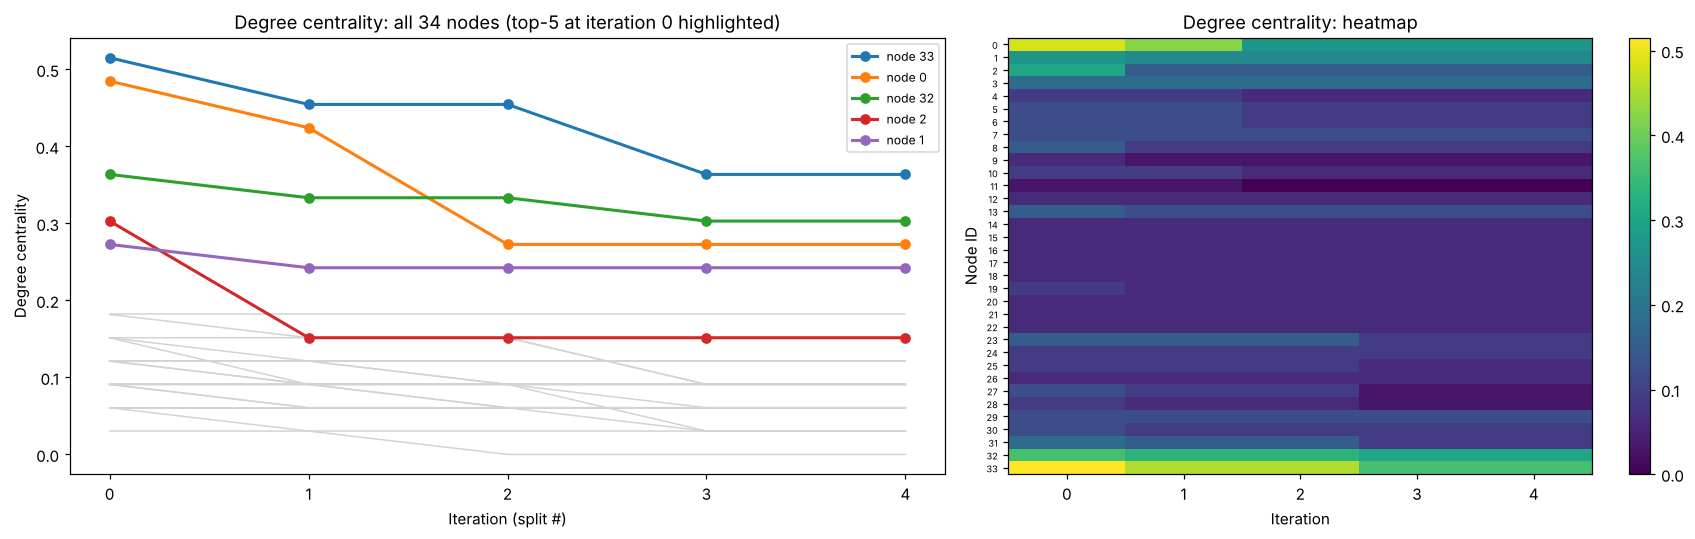

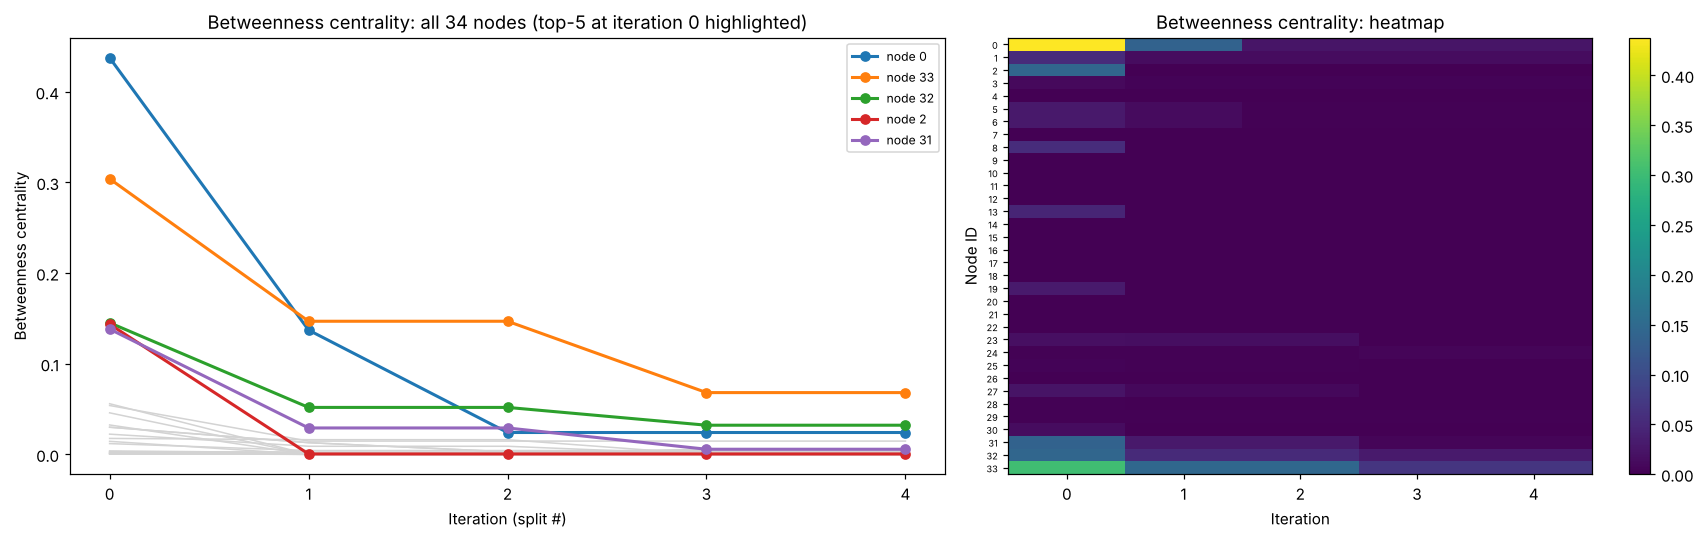

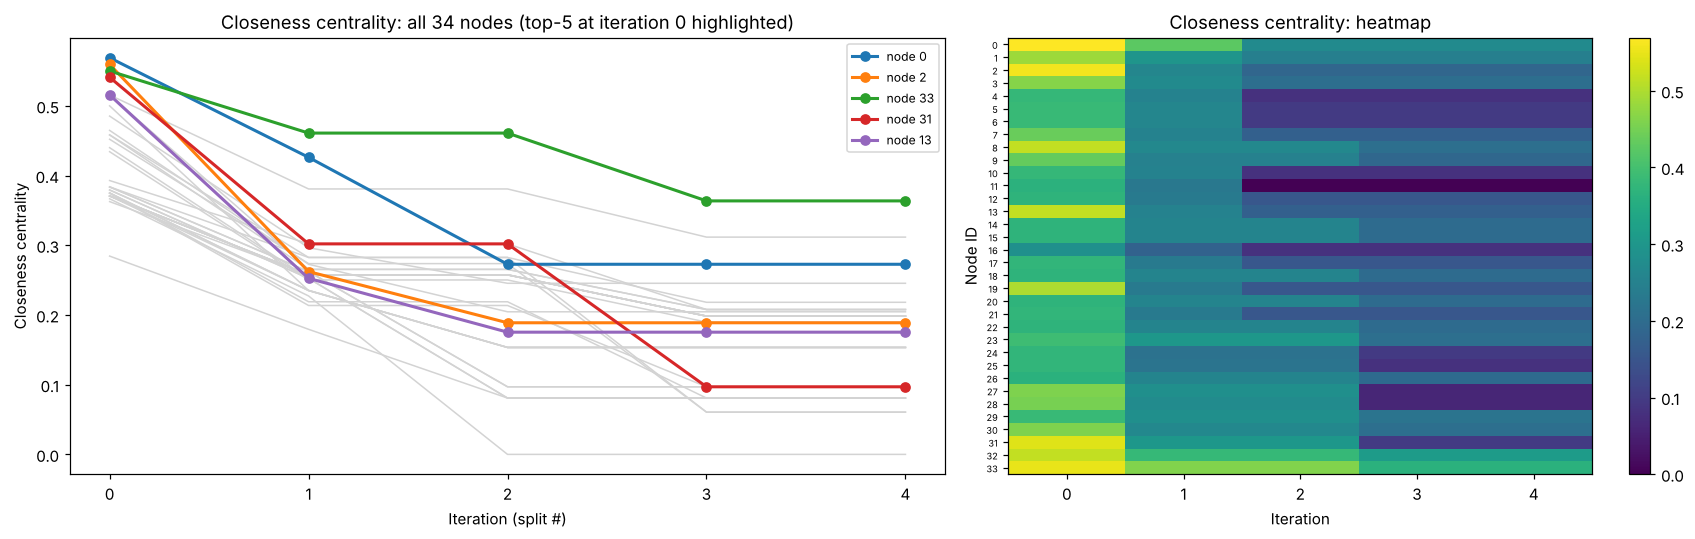

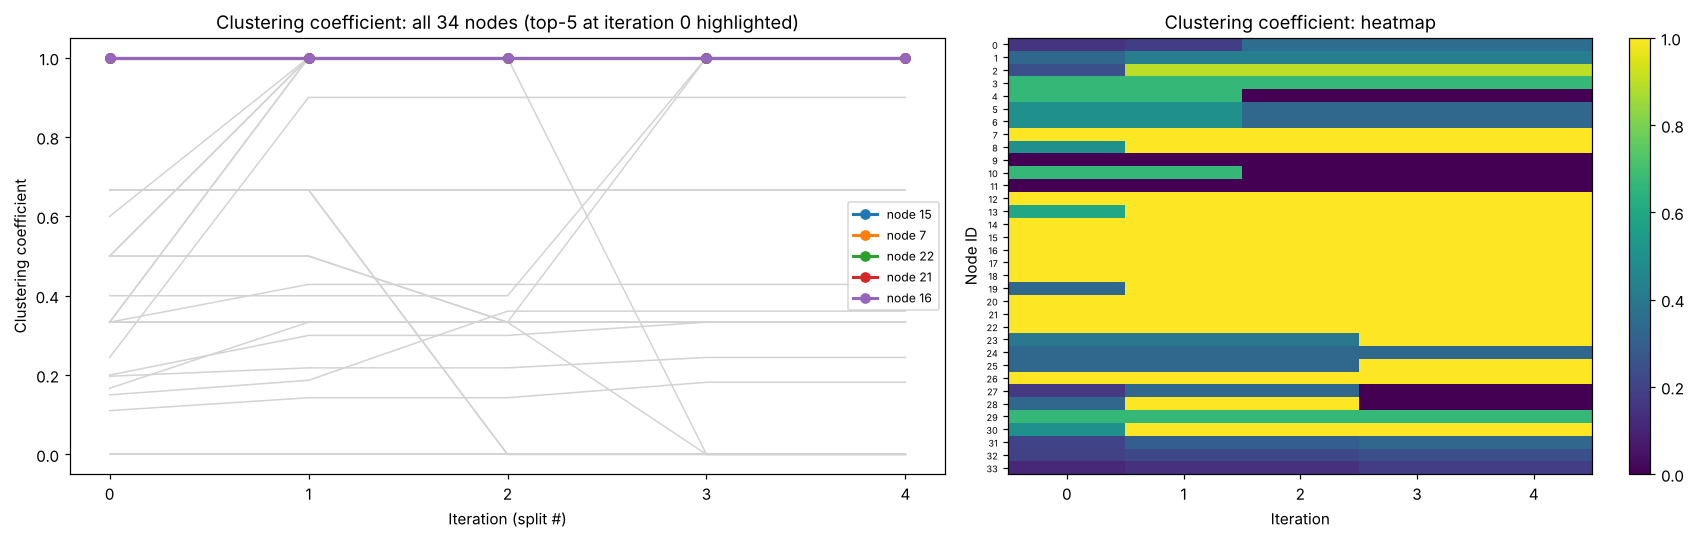

In [9]:
top_n = 5
for name, df in tables.items():
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1.2, 1]})
    # (a) line plot: all nodes in grey, top-5 (by iteration-0 value) highlighted
    ax = axes[0]
    top = df.iloc[0].sort_values(ascending=False).head(top_n).index
    for v in df.columns:
        if v not in top: ax.plot(df.index, df[v], color='lightgrey', lw=1)
    for v in top: ax.plot(df.index, df[v], marker='o', lw=2, label=f"node {v}")
    ax.set_xticks(df.index); ax.set_xlabel('Iteration (split #)'); ax.set_ylabel(name)
    ax.set_title(f"{name}: all 34 nodes (top-{top_n} at iteration 0 highlighted)"); ax.legend(fontsize=8)
    # (b) heatmap: every node, every iteration
    ax = axes[1]
    im = ax.imshow(df.values.T, aspect='auto', cmap='viridis')
    ax.set_yticks(range(n)); ax.set_yticklabels(df.columns, fontsize=6)
    ax.set_xticks(range(len(df.index))); ax.set_xlabel('Iteration'); ax.set_ylabel('Node ID')
    ax.set_title(f"{name}: heatmap"); plt.colorbar(im, ax=ax)
    plt.tight_layout(); plt.show()

### Per-node trajectories (grid view, every node labeled)

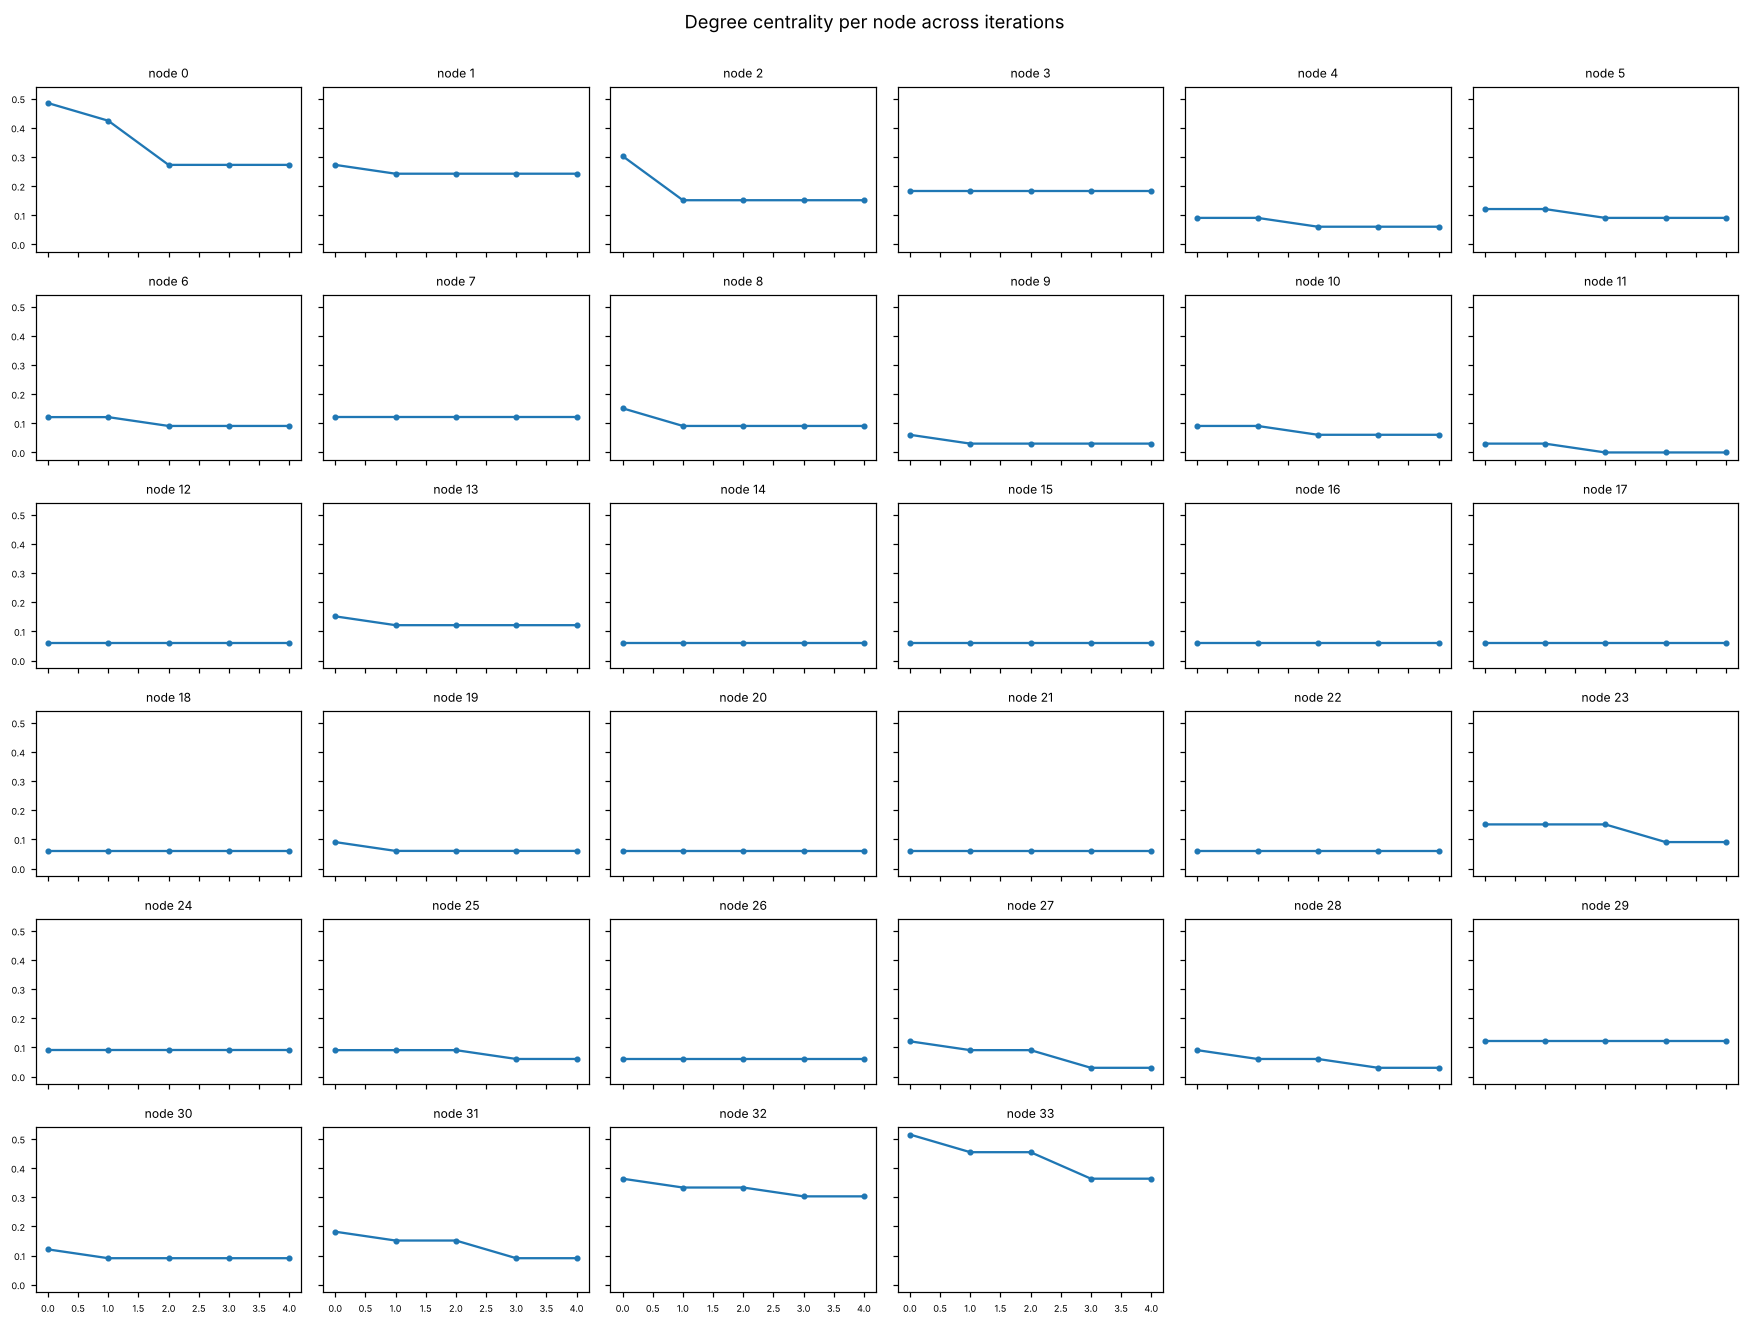

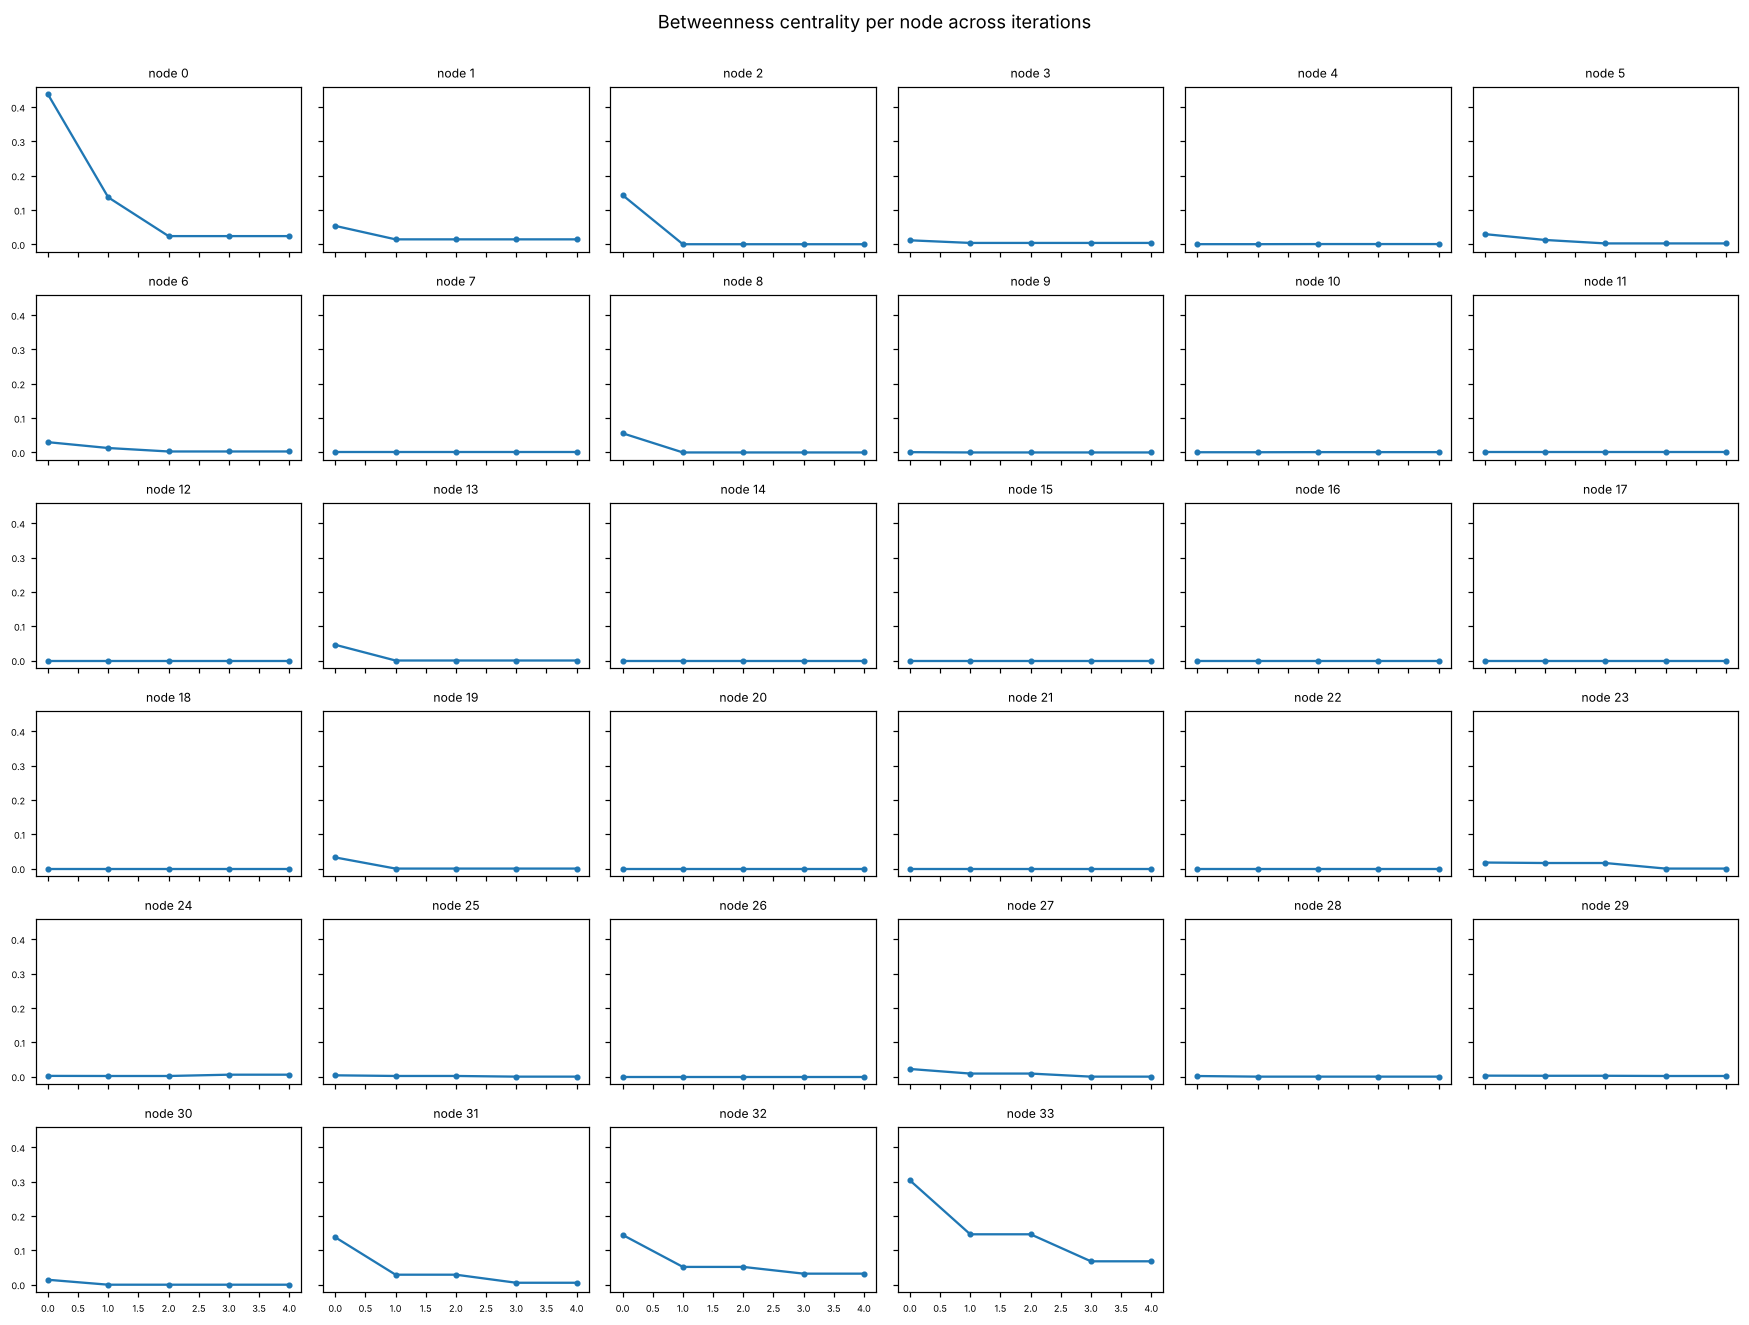

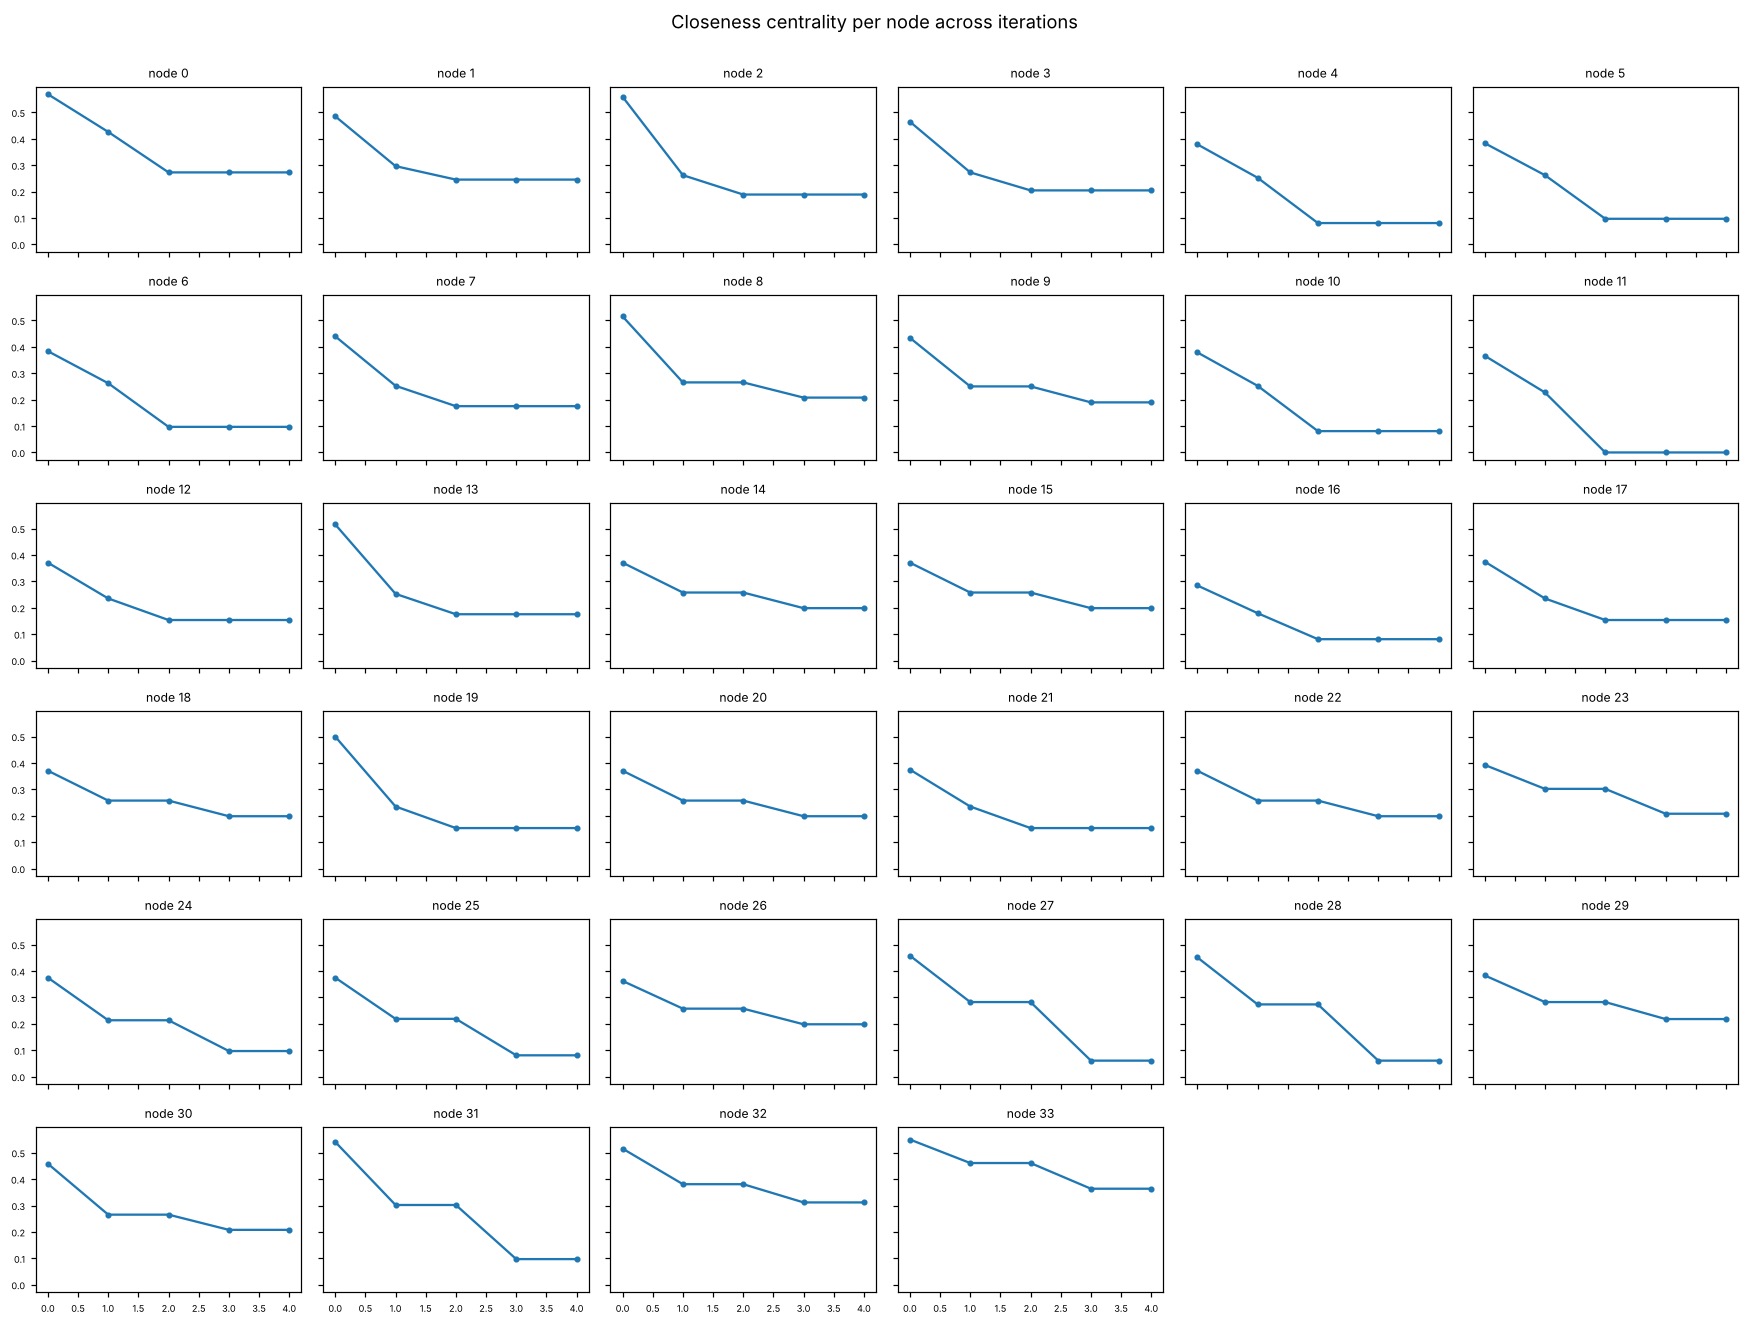

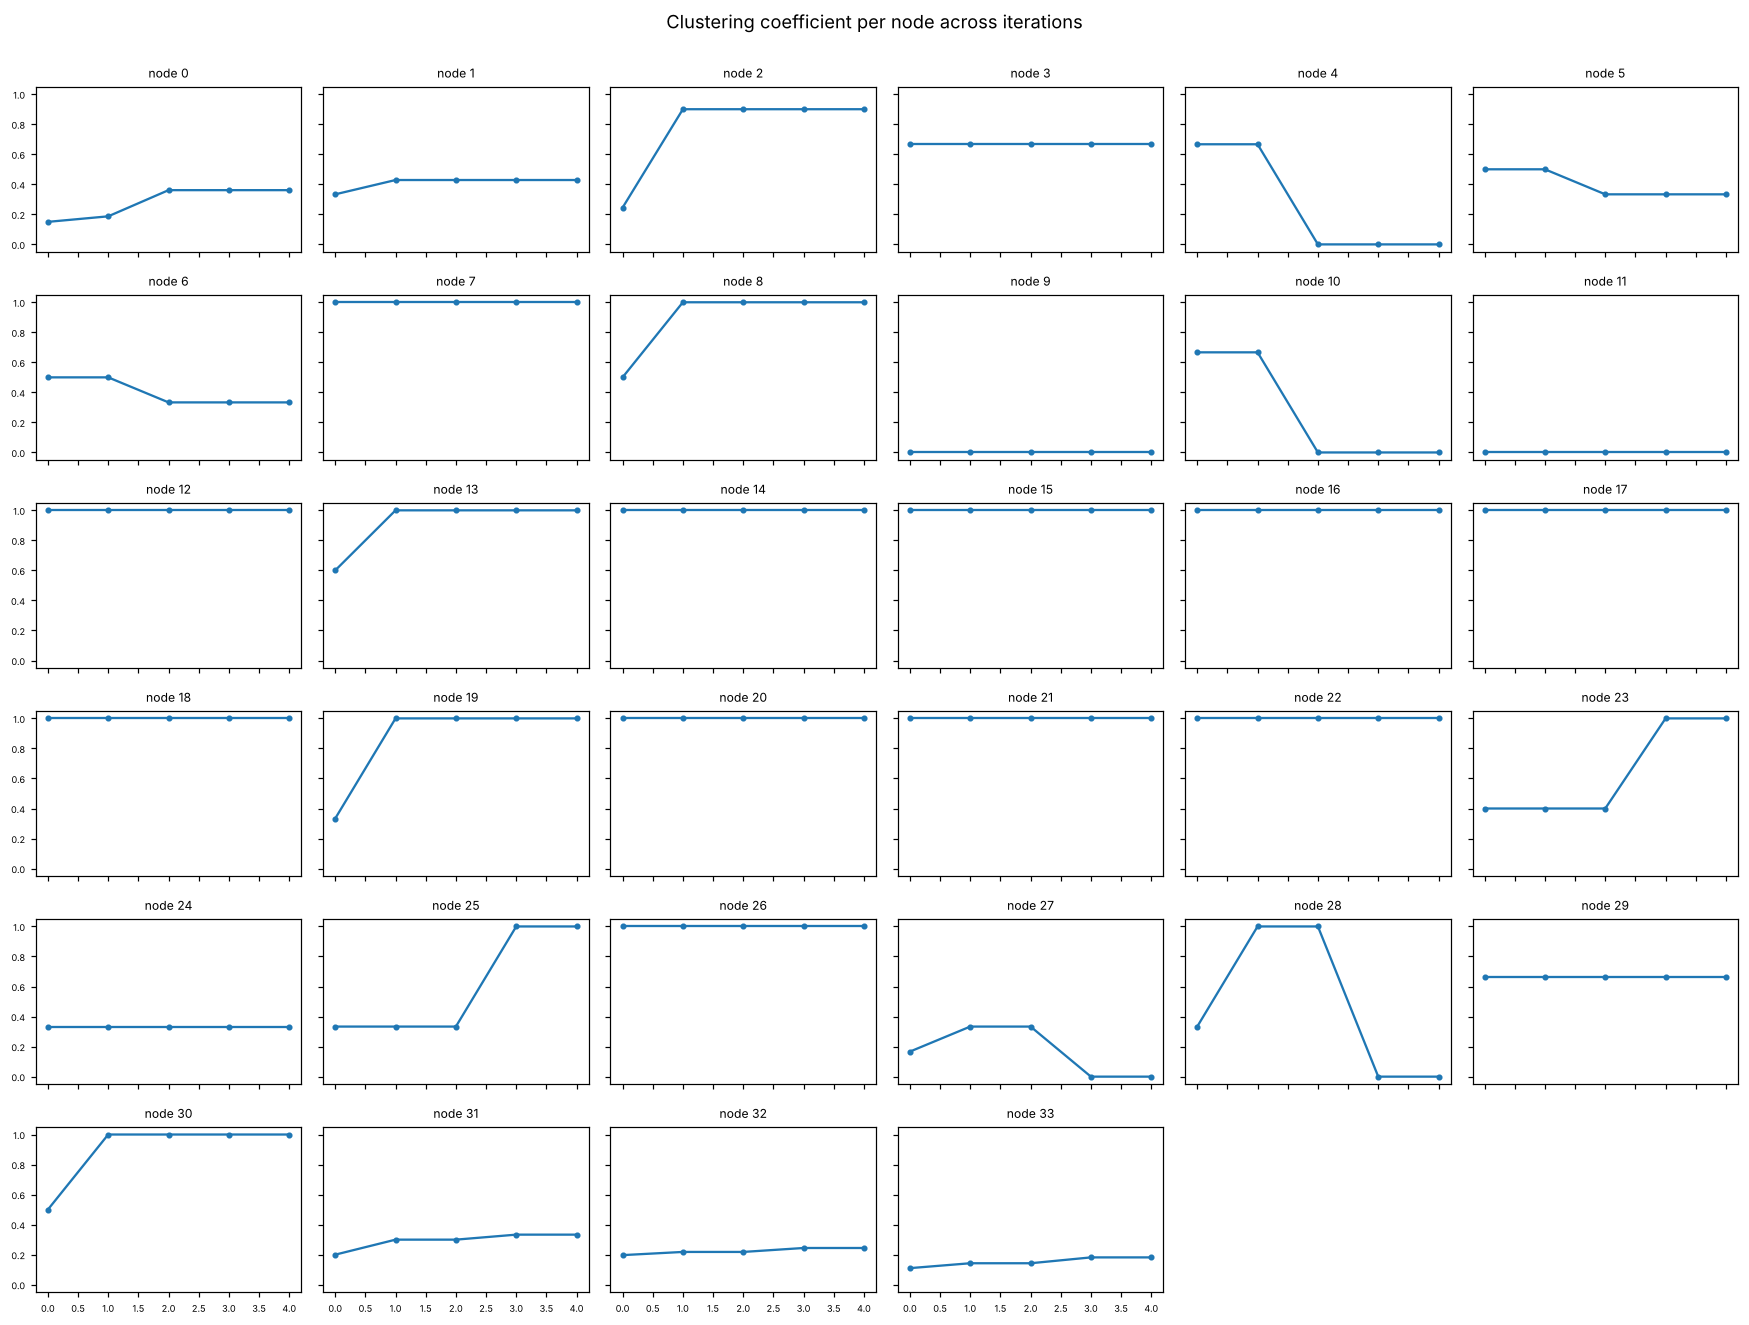

In [10]:
for name, df in tables.items():
    fig, axes = plt.subplots(6, 6, figsize=(16, 12), sharex=True, sharey=True)
    for v, ax in zip(df.columns, axes.ravel()):
        ax.plot(df.index, df[v], marker='o', ms=3)
        ax.set_title(f"node {v}", fontsize=8); ax.tick_params(labelsize=6)
    for ax in axes.ravel()[n:]: ax.axis('off')
    fig.suptitle(f"{name} per node across iterations", y=1.0); plt.tight_layout(); plt.show()

## 7. Which nodes stay central?

In [11]:
summary = pd.DataFrame({
    f"{name} (mean over iters)": df.mean() for name, df in tables.items()
})
# rank each node by its average rank across the four metrics
ranks = pd.DataFrame({name: df.rank(axis=1, ascending=False).mean() for name, df in tables.items()})
summary['avg rank (lower = more central)'] = ranks.mean(axis=1)
summary['final community'] = [next(i+1 for i, g in enumerate(sorted(communities, key=lambda c: c[0])) if v in g) for v in summary.index]
summary['club'] = [truth[v] for v in summary.index]
summary.sort_values('avg rank (lower = more central)').head(8).round(3)

,Degree centrality (mean over iters),Betweenness centrality (mean over iters),Closeness centrality (mean over iters),Clustering coefficient (mean over iters),avg rank (lower = more central),final community,club
33,0.430,0.147,0.440,0.152,8.40,3,Officer
0,0.345,0.129,0.363,0.284,8.55,1,Mr. Hi
32,0.327,0.063,0.380,0.224,9.05,3,Officer
1,0.248,0.023,0.304,0.410,9.95,1,Mr. Hi
3,0.182,0.006,0.270,0.667,11.15,1,Mr. Hi
29,0.121,0.002,0.277,0.667,12.05,3,Officer
23,0.127,0.010,0.282,0.640,12.15,3,Officer
2,0.182,0.029,0.278,0.769,13.05,1,Mr. Hi


In [12]:
# change between the initial graph and the final partition
delta = pd.DataFrame({name: df.iloc[-1] - df.iloc[0] for name, df in tables.items()}).round(3)
print("Nodes whose metrics changed the most (final - initial):")
for name in delta.columns:
    print(f"  {name:24s} biggest drop: node {delta[name].idxmin()} ({delta[name].min():+.3f}) | biggest rise: node {delta[name].idxmax()} ({delta[name].max():+.3f})")

Nodes whose metrics changed the most (final - initial):
  Degree centrality        biggest drop: node 0 (-0.212) | biggest rise: node 3 (+0.000)
  Betweenness centrality   biggest drop: node 0 (-0.413) | biggest rise: node 24 (+0.003)
  Closeness centrality     biggest drop: node 31 (-0.444) | biggest rise: node 26 (-0.164)
  Clustering coefficient   biggest drop: node 4 (-0.667) | biggest rise: node 19 (+0.667)


## 8. Bonus: handout block vs. Newman's corrected `B(C)`

The handout takes the plain block of `B`. Newman's paper subtracts the row sums on the diagonal so that `ΔQ` is exact for the *whole-graph* modularity. Let's see whether it changes the answer here.

Newman-corrected generalized modularity matrix:
  group of size 34: lambda1 =  4.9771 -> split 16 / 18   (dQ = 0.3715)
  group of size 16: lambda1 =  1.1785 -> split 7 / 9   (dQ = 0.0012)
  group of size 18: lambda1 =  0.8594 -> split 12 / 6   (dQ = 0.0207)
  group of size  7: lambda1 = -0.0000 -> indivisible
  group of size  9: lambda1 =  0.0602 -> indivisible
  group of size 12: lambda1 = -0.0000 -> indivisible
  group of size  6: lambda1 =  0.0000 -> indivisible

Found 4 communities, Q = 0.3934   (handout version: 5 communities, Q = 0.4094)
  C1: [0, 4, 5, 6, 10, 11, 16]
  C2: [1, 2, 3, 7, 12, 13, 17, 19, 21]
  C3: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  C4: [23, 24, 25, 27, 28, 31]


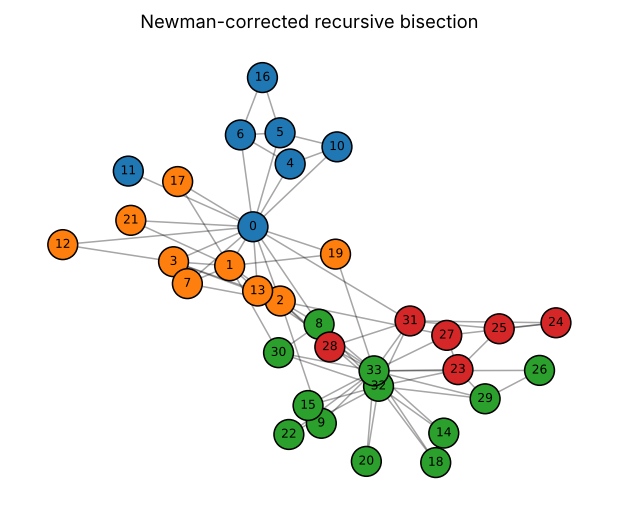

In [13]:
print("Newman-corrected generalized modularity matrix:")
comm2, hist2, log2 = recursive_bisection(B, newman_correction=True)
print(f"\nFound {len(comm2)} communities, Q = {modularity_Q(comm2):.4f}   (handout version: {len(communities)} communities, Q = {modularity_Q(communities):.4f})")
for i, c in enumerate(sorted(comm2, key=lambda c: c[0])): print(f"  C{i+1}: {c}")
fig, ax = plt.subplots(figsize=(7, 5.5)); draw_partition(comm2, "Newman-corrected recursive bisection", ax); plt.show()

## 9. Discussion

### What the algorithm found
* **Iteration 1 (first split, λ₁ ≈ 4.98)** gives groups of 16 and 18 nodes with **Q ≈ 0.371**. This matches the real club fission on **33 of 34 members**; only **node 8** is misclassified (the well-known "hard" member who has ties to both camps). The spectral method recovers the split using only the pre-split friendship graph.
* Further splits raise Q to **0.4094** with **5 communities** (`[0,1,2,3,7,12,13,17,19,21]`, `[4,5,6,10,16]`, `[8,9,14,15,18,20,22,23,26,29,30,32,33]`, `[24,25,27,28,31]`, `[11]`). The gains are small after the first split (0.371 → 0.390 → 0.408 → 0.409), so the 2-faction structure dominates; the finer groups are sub-cliques inside each faction (e.g. `{4,5,6,10,16}` is a tight clique around Mr. Hi's side).
* **Caveat about the handout's formula.** The handout restricts `B` to the block `B(C)` and calls `sᵀB(C)s/4m` the modularity gain. Newman's paper actually uses `B⁽ᶜ⁾_ij = B_ij − δ_ij Σ_{l∈C} B_il`, which makes ΔQ exact. Section 8 shows that this corrected version gives 4 communities with Q ≈ 0.393. Here, the handout version happens to reach a slightly higher Q (0.409), but its printed "ΔQ" values are not exact gains, which is why some are negative even though λ₁ > 0 (the plain block is not guaranteed to satisfy Theorem 3's gain identity). Both versions agree on the first split.

### Which nodes remain central?
* **Nodes 33 and 0** (the president / "Officer" and Mr. Hi) and **node 32** are the persistently central nodes. They hold the top spots in degree, betweenness and closeness at almost every iteration, and have the best average rank across the four metrics (33 ≈ 8.4, 0 ≈ 8.6, 32 ≈ 9.1, then node 1).
* **Node 0** is the clearest case of how splitting changes things: its degree centrality drops 0.485 → 0.273 and its betweenness collapses 0.438 → 0.024, because after the first splits it lost its bridging role to the other faction and to the cut-off branch around nodes 4, 5, 6, 10, 16 and 11. It is still a hub *inside* its own community, but no longer a broker for the whole network.
* **Node 33** is more stable: degree 0.515 → 0.364 and betweenness 0.304 → 0.068. His community (13 nodes) is the largest and he is its centre, so he keeps the top rank in all three path-based metrics at the end.
* **Nodes 8, 31, 2** (closeness/betweenness top-5 at the start) fall sharply. They were "bridges" between the factions whose edges are removed by the cut; e.g. node 31's betweenness falls from 0.138 to 0.006.
* **Node 11** is only linked to node 0, so after it is separated it has degree = closeness = clustering = 0 (a singleton community).

### How community structure influences each metric
* **Degree centrality** can only decrease (edges between communities are removed). Hubs lose the most when many of their neighbours end up in another group; nodes whose neighbours stay together (e.g. node 3) are unchanged.
* **Betweenness and closeness** change the most, because they depend on global shortest paths. Once communities become disconnected, paths across the cut vanish, so "bridge" nodes lose betweenness and everyone's closeness falls (with the Wasserman–Faust scaling used by NetworkX). What survives is *local* importance within a community.
* **Clustering coefficient** behaves in the opposite way: it often **rises** (e.g. node 2: 0.244 → 0.900, node 8: 0.5 → 1.0) because the removed inter-community edges were the ones that reduced triangle density. Cohesive nodes inside tight groups stay at or near 1, while leaders and brokers (0, 33) have low clustering because their neighbourhoods span several sub-groups. A node can be central **or** embedded in a clique, but rarely both, which is the classic hub-vs-clique trade-off.
* **Overall:** community detection separates *global* importance (hubs and brokers: 0, 33, 32) from *local* cohesion (members of tight cliques such as 4, 5, 6, 10, 16, which have high clustering but modest centrality).

*Design note: metrics at each iteration are computed on the graph with inter-community edges removed (see Section 5), so they describe each node's position within its own community.*


## References
* M. E. J. Newman, "Modularity and community structure in networks", *PNAS* 103(23):8577–8582, 2006.
* W. W. Zachary, "An information flow model for conflict and fission in small groups", *J. Anthropological Research* 33(4):452–473, 1977.
* NetworkX documentation: https://networkx.org